# exploration traindataset 

In [9]:
# libraries
import plotly.express as px
import plotly.io as pio
import matplotlib.pyplot as plt
import pandas as pd

# setup
pio.templates.default="gridon"

# global variables
CORPUS_PATH = "../corpora-collection/sunset-corpus/src/normalized/"
COLOR_VIRIDIS=["#fde725", "#21918c", "#440154"]

In [4]:
df = pd.read_csv("src/city_country_metadata.tsv", sep="\t")
df.columns

Index(['ID', 'filename', 'title', 'author', 'gnd', 'birthYear', 'deathYear',
       'gender', 'source', 'pubYear', 'label', 'Source_Genre', 'textClass',
       'genre'],
      dtype='str')

In [3]:
len(df)

4428

In [8]:
df.gender.value_counts()

gender
männlich    142
weiblich     14
Name: count, dtype: int64

In [40]:
df.loc[df.textClass=="Urban"].gender.value_counts()

gender
männlich    53
weiblich     3
Name: count, dtype: int64

In [16]:
for subset in df.textClass.unique():
    sliceDf = df.loc[df.textClass==subset]

    token_count = 0

    for file in sliceDf.filename:
        with open(CORPUS_PATH + file) as f:
            text = f.read()
        token_count = token_count + len(text.split())

    print(subset, "\tn files: ", len(sliceDf), "\tn tokens: ", token_count)
    print("\tn authors", len(sliceDf.author.unique()), "\tn male", len(sliceDf.loc[sliceDf.gender=="männlich"].author.unique()), "\tn female", len(sliceDf.loc[sliceDf.gender=="weiblich"].author.unique()),)
    print("\tfrom: ", sliceDf.pubYear.min(), "\tto: ", sliceDf.pubYear.max())

Urban 	n files:  56 	n tokens:  6181031
	n authors 25 	n male 22 	n female 3
	from:  1819 	to:  1935
Rural 	n files:  61 	n tokens:  4853519
	n authors 38 	n male 32 	n female 6
	from:  1781 	to:  1918
Other 	n files:  39 	n tokens:  2075385
	n authors 21 	n male 20 	n female 1
	from:  1797 	to:  1919


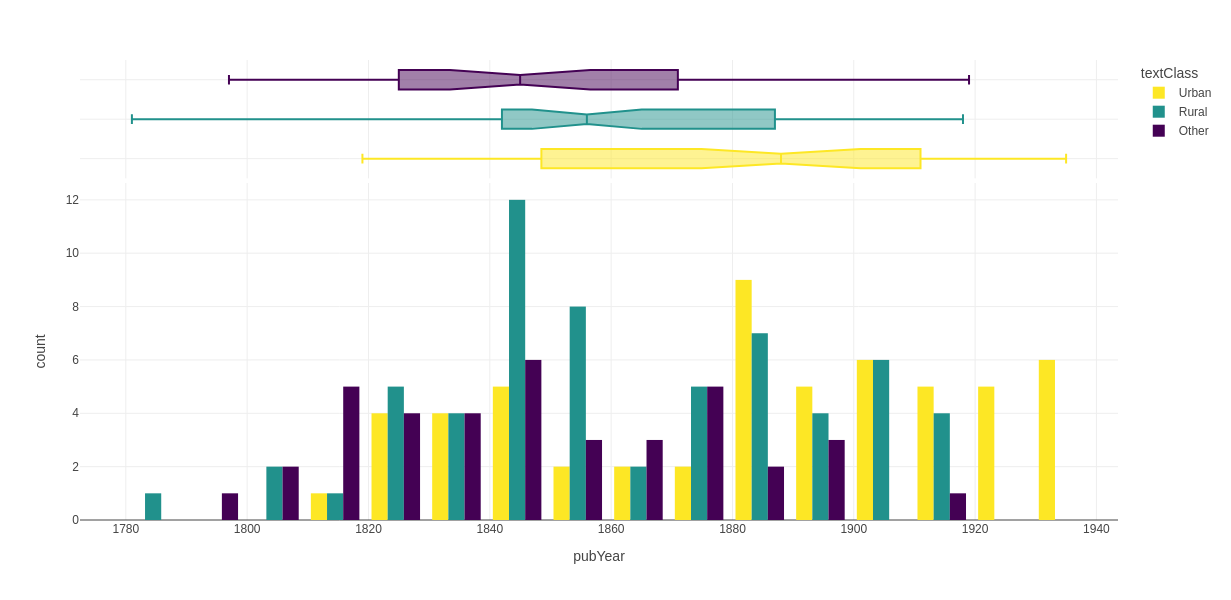

In [10]:
px.histogram(df,
             x="pubYear",
             color="textClass",
             color_discrete_sequence=COLOR_VIRIDIS,
             barmode='group',
             marginal="box",
             height=600)

In [12]:
ds = pd.read_csv("src/results-merged-meta.tsv", sep="\t")
ds.columns

Index(['filename', 'ID', 'title', 'gndID', 'author', 'birthYear', 'deathYear',
       'gender', 'nationality', 'pubYear', 'numTokens', 'timeslotPubYear',
       'timeslotBirthYear', 'source', 'n_chunks', 'textClass',
       'mean_prob_prose', 'mean_prob_drama', 'mean_prob_lyric', 'corpusSubset',
       'prediction'],
      dtype='str')

In [16]:
ds = ds.loc[(ds.textClass=="prose")&(~ds.pubYear.isna())]

In [17]:
len(ds)

1900

In [18]:
ds.gender.value_counts()

gender
männlich    1695
weiblich     205
Name: count, dtype: int64

In [19]:
len(ds.author.unique())

455

In [21]:
ds.drop_duplicates(subset="author").gender.value_counts()

gender
männlich    372
weiblich     83
Name: count, dtype: int64

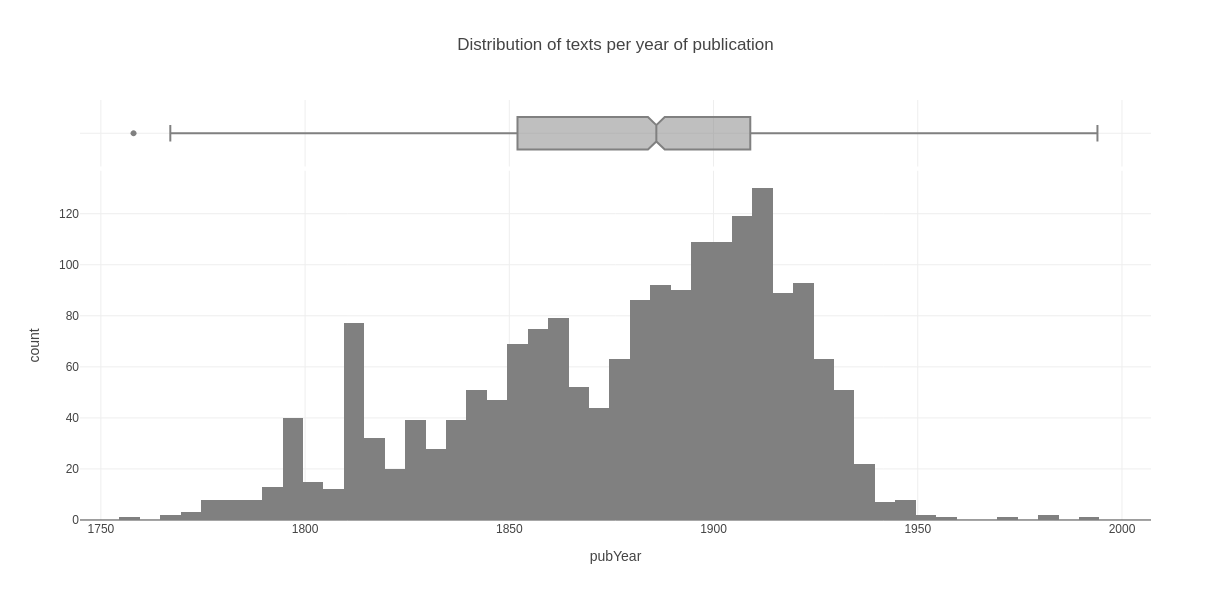

In [44]:
px.histogram(ds,
             x="pubYear",
             marginal="box",
             color_discrete_sequence=["grey"],
             width=800,
             height=600,
             title = "Distribution of texts per year of publication",
            )

In [29]:
n_tokens = 0
for file in meta.filename:
    with open("../../GitHub/corpora-collection/sunset-corpus/src/raw/"+file) as f:
        text = f.read()
    n_tokens=n_tokens +len(text.split())
n_tokens

227513212

In [34]:
df["subset"]=df.textClass

In [35]:
ds["subset"]="complete"

In [42]:
ds.loc[ds.filename.isin(df.loc[df.textClass=="Other"].filename)]

,filename,ID,title,gndID,author,birthYear,deathYear,gender,nationality,pubYear,...,timeslotBirthYear,source,n_chunks,textClass,mean_prob_prose,mean_prob_drama,mean_prob_lyric,corpusSubset,prediction,subset


In [37]:
new_df = pd.concat([ds, df])
new_df

,filename,ID,title,gndID,author,birthYear,deathYear,gender,nationality,pubYear,...,mean_prob_prose,mean_prob_drama,mean_prob_lyric,corpusSubset,prediction,subset,gnd,label,Source_Genre,genre
1,kid30767.txt,1,Die Höhlenkinder – Im Pfahlbau,http://d-nb.info/gnd/119410885,A. Th. Sonnleitner,1869,1939,männlich,Tschechische Republik; Österreich,1918.0,...,0.969230,0.019879,0.010891,wide,Other,complete,NaN,NaN,NaN,NaN
14,Arnim_DerWintergarten_zeno.txt,18,Der Wintergarten,http://d-nb.info/gnd/118504177,Achim von Arnim,1784,1834,männlich,Deutschland,1809.0,...,0.780461,0.091525,0.128014,core,Rural,complete,NaN,NaN,NaN,NaN
25,Arnim_FrauvonSaverne.txt,33,Frau von Saverne,http://d-nb.info/gnd/118504177,Achim von Arnim,1789,1839,männlich,Deutschland,1817.0,...,0.981916,0.017376,0.000708,wide,Other,complete,NaN,NaN,NaN,NaN
27,kid35132.txt,35,Holländische Liebhabereien,http://d-nb.info/gnd/118504177,Achim von Arnim,1781,1831,männlich,Deutschland,1826.0,...,0.901720,0.059111,0.039169,wide,Rural,complete,NaN,NaN,NaN,NaN
28,Arnim_Hollin'sLiebeleben.txt,36,Hollin's Liebeleben,http://d-nb.info/gnd/118504177,Achim von Arnim,1790,1840,männlich,Deutschland,1802.0,...,0.770344,0.160608,0.069048,wide,Urban,complete,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
151,Meyer_GustavAdolfsPage_zeno.txt,152,Gustav Adolfs Page,NaN,Conrad Ferdinand Meyer,1825,1898,männlich,NaN,1883.0,...,NaN,NaN,NaN,NaN,NaN,Other,http://d-nb.info/gnd/118581775,2.0,manual addition,NaN
152,kid31162.txt,153,Die Menschenfabrik,NaN,Oskar Panizza,1853,1921,männlich,NaN,1890.0,...,NaN,NaN,NaN,NaN,NaN,Other,http://d-nb.info/gnd/118739131,2.0,manual addition,NaN
153,May_DerSchatzimSilbersee.txt,154,Der Schatz im Silbersee,NaN,Karl May,1842,1912,männlich,NaN,1891.0,...,NaN,NaN,NaN,NaN,NaN,Other,http://d-nb.info/gnd/118818651,2.0,manual addition,NaN
154,lasswitz_planeten01_1897.txt,155,Auf zwei Planeten,NaN,Kurd Laßwitz,1848,1910,männlich,NaN,1897.0,...,NaN,NaN,NaN,NaN,NaN,Other,http://d-nb.info/gnd/118569961,2.0,manual addition,NaN


In [38]:
new_df.pubYear.isna().value_counts()

pubYear
False    2056
Name: count, dtype: int64

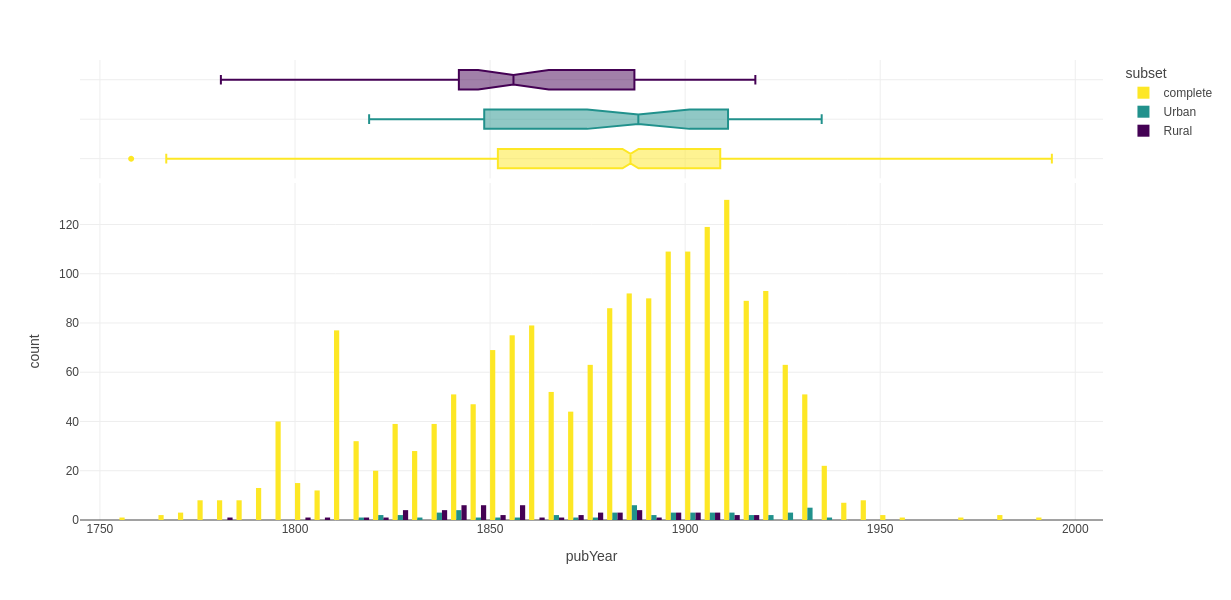

In [40]:
from plotly.subplots import make_subplots

px.histogram(new_df.loc[~(new_df.subset=="Other")],
             x="pubYear",
             color="subset",
             color_discrete_sequence=COLOR_VIRIDIS,
             barmode='group',
             marginal="box",
             height=600)